# Computer Vision MM 2026 - Practical 1 (v1.0)

## Instructions

1. Start Google Colab: https://colab.research.google.com. A modal dialog should have appeared to open a new notebook. If not, go to "File>Open notebook".
2. From the open notebook dialog, select the GitHub "tab" and enter this URL: https://github.com/chrirupp/cv_course
3. The notebook(s) should appear (*.ipynb). Select the one for the current practical.
4. To run a notebook on Colab you will typically need some data files (e.g., images). As Colab only loads the notebook itself, these other files need to be downloaded separately. The following cell is a `%%sh` block that downloads the required files. You can inspect the downloaded files by clicking on the "Files" tab on the left.

## Practicalities

The signing-off happens in the last half hour of each session or at the beginning of the following one.
As usual, when checking your work the demonstrator will want to see a working version of the program in action, as well as appropriate comments of your code. Try to make your report as concise as possible, perhaps in the form of appropriate comments to your code.

Since this is a new practical task, any errors, ambiguities or suggestions for improvement should be flagged as soon as possible.

If you are not familiar with the way practicals run, there are department-wide [rules](https://www.cs.ox.ac.uk/teaching/courses/2026-2027/practicals/). There you will find how the compulsory part, the optional tasks, and your report will factor into your mark.

## Advice

* You will need to look at the code for the lectures. There you will find many related computations that you can reuse and adapt to solve the practicals.
* The compulsory part of this practical is designed to give you additional understanding of the concepts taught in the lectures. It should be achievable in one session.

In [6]:
%%sh
# Download the data - you need to do this only once
wget --no-verbose --output-document=image.jpg https://github.com/chrirupp/cv_course/raw/main/data/image.jpg
wget --no-verbose --output-document=image_cc_1.jpg https://github.com/chrirupp/cv_course/raw/main/data/image_cc_1.jpg
wget --no-verbose --output-document=image_cc_2.jpg https://github.com/chrirupp/cv_course/raw/main/data/image_cc_2.jpg
wget --no-verbose --output-document=image_cc_3.jpg https://github.com/chrirupp/cv_course/raw/main/data/image_cc_3.jpg

2026-10-27 09:27:52 URL:https://raw.githubusercontent.com/chrirupp/cv_course/main/data/image.jpg [266057/266057] -> "image.jpg" [1]
2026-10-27 09:27:52 URL:https://raw.githubusercontent.com/chrirupp/cv_course/main/data/image_cc_1.jpg [12561742/12561742] -> "image_cc_1.jpg" [1]
2026-10-27 09:27:53 URL:https://raw.githubusercontent.com/chrirupp/cv_course/main/data/image_cc_2.jpg [13042668/13042668] -> "image_cc_2.jpg" [1]
2026-10-27 09:27:54 URL:https://raw.githubusercontent.com/chrirupp/cv_course/main/data/image_cc_3.jpg [15192593/15192593] -> "image_cc_3.jpg" [1]


Here we import some libraries that we will need to process images, do maths, and to visualise results.

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import copy
import random
from tqdm import tqdm
%matplotlib inline

Here are some helper functions that will help us visualise and analyse what is going on. This code is also found in the code for the lectures.

In [8]:
class Visualizer():
    def __init__(self, num_rows=1, num_cols=1, figsize=(5,5), axis_off=True, title='', tight=False, cm=None):
        fig, self.axs = plt.subplots(num_rows, num_cols, figsize=figsize, squeeze=False)
        # remove ticks
        if axis_off:
          plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
        # set colormap
        if cm is not None:
            plt.set_cmap(cm)
        # set supertitle
        fig.suptitle(title)
        if tight:
            fig.subplots_adjust(top=0.88)

    def add_image_subplot(self, i, j, image, normalize=False, title_str=''):
        if normalize:
            image = self.normalize_image(image)
        if len(image.shape) == 3:
            #BGR -> RGB
            image = image[:, :, ::-1]
        self.axs[i, j].imshow(image)
        self.axs[i, j].set_title(title_str)

    def add_stem_subplot(self, i, j, x, y, title_str=''):
        self.axs[i, j].stem(x, y)
        self.axs[i, j].set_title(title_str)

    def add_subplot(self, i, j, data, title_str=''):
        self.axs[i, j].plot(data)
        self.axs[i, j].set_title(title_str)

    def add_bar_subplot(self, i, j, x, y, title_str=''):
        self.axs[i, j].bar(x, y)
        self.axs[i, j].set_title(title_str)

    @staticmethod
    def normalize_image(image):
        img = np.float64(image) - np.min(image)
        img /= np.max(img)
        return img

## Problem 1.1 - Template Matching

We load a photo of Christ Church Meadow Building (downsampled to make things fast) and cut out a template: the crest above the gate. We already know where the template is, so we can check whether the different energy functions find it.

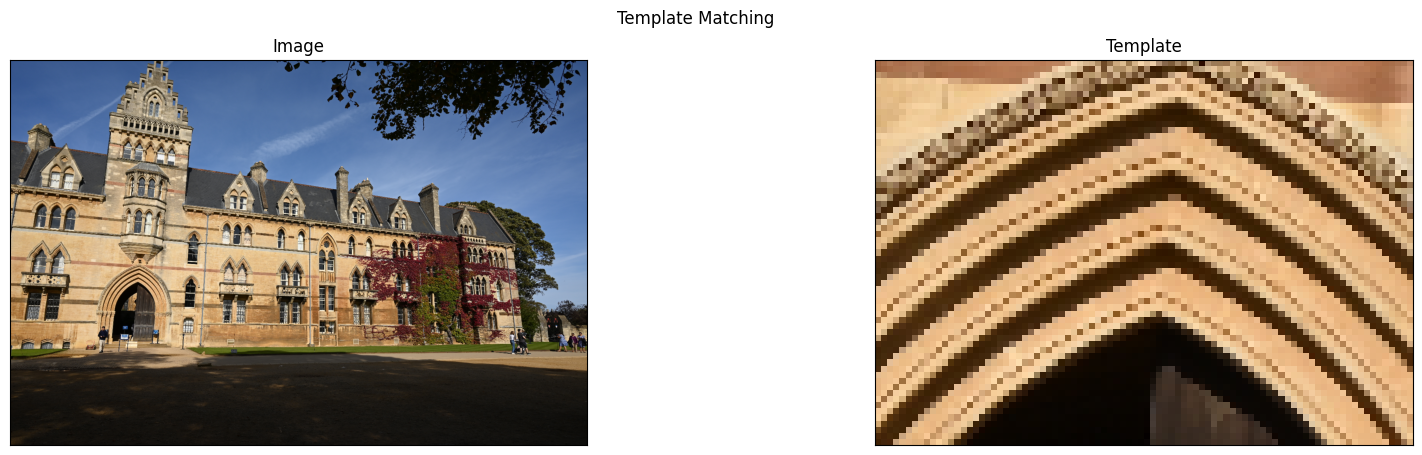

In [9]:
downsample = 0.25
image = cv2.resize(cv2.imread('image_cc_2.jpg'), (0, 0), fx=downsample, fy=downsample)
image_gray = np.float32(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY))
x0, y0, w, h = 287, 537, 88, 63  # top-left corner (x, y), width and height of the template
template = image[y0:y0 + h, x0:x0 + w]
template_gray = image_gray[y0:y0 + h, x0:x0 + w]

def show_detection(energy, x, y, title):
    result_image = image.copy()
    cv2.rectangle(result_image, (x, y), (x + w, y + h), (0, 0, 255), 3)
    vis = Visualizer(1, 2, figsize=(20, 5), title=title)
    vis.add_image_subplot(0, 0, energy, title_str='Energy')
    vis.add_image_subplot(0, 1, result_image, title_str=f'Detection at (x, y) = ({x}, {y})')

vis = Visualizer(1, 2, figsize=(20, 5), title='Template Matching')
vis.add_image_subplot(0, 0, image, title_str='Image')
vis.add_image_subplot(0, 1, template, title_str='Template')

OpenCV implements template matching for us in `cv2.matchTemplate`, a fast C++ implementation. It accepts several energy functions. We start with the sum of squared differences (SSD) from the lecture and Sheet 1. Note that NumPy arrays are indexed `[row, column]`, i.e. `[y, x]`, while OpenCV drawing functions expect points as `(x, y)`.

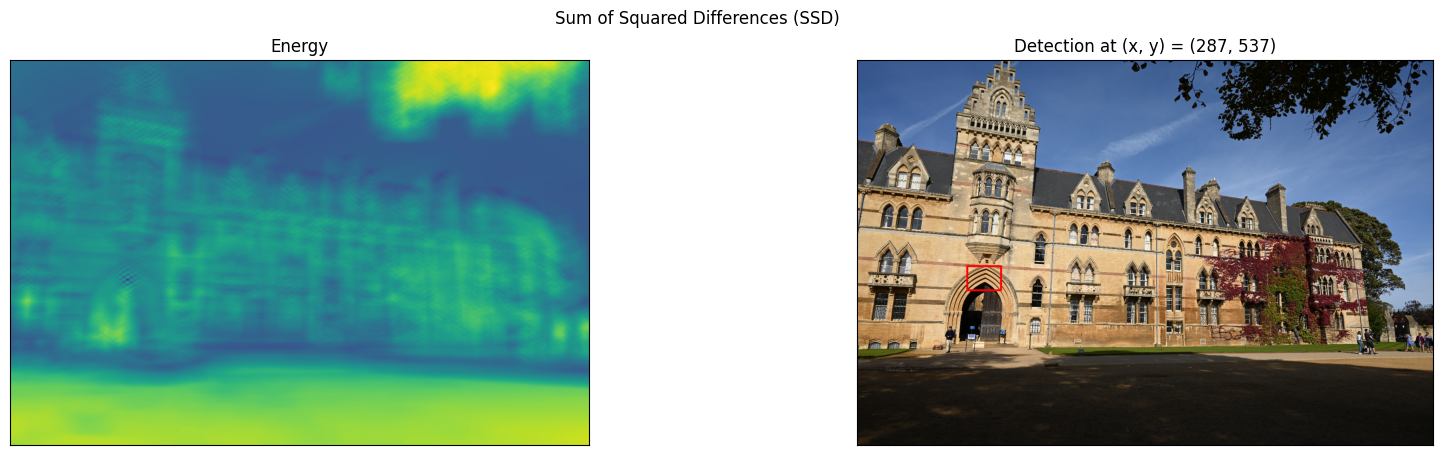

In [10]:
energy_ssd = cv2.matchTemplate(image_gray, template_gray, cv2.TM_SQDIFF)
y, x = np.unravel_index(energy_ssd.argmin(), energy_ssd.shape)
show_detection(energy_ssd, x, y, 'Sum of Squared Differences (SSD)')

In Sheet 1 (Q1.4) you showed that SSD can be computed with convolutions:
$$E(x,y) = \sum_{i,j} T(i,j)^2 - 2 \sum_{i,j} T(i,j)\, I(x+i, y+j) + \sum_{i,j} I(x+i,y+j)^2 .$$
Implement SSD this way and check that it agrees with OpenCV:
* the middle sum is a correlation: `cv2.matchTemplate(..., cv2.TM_CCORR)` computes it,
* the last sum is a box filter on $I^2$: use `cv2.boxFilter` with `normalize=False`. Be careful with the `anchor` and `borderType` arguments so that the output is aligned with the top-left corner convention of `matchTemplate`, and crop it to the same size.

In [11]:
import cv2
import numpy as np
def ssd_by_convolution(image_gray, template_gray):
    # TODO: implement SSD with a correlation and a box filter
    img = image_gray.astype(np.float32)
    tpl = template_gray.astype(np.float32)

    h, w = tpl.shape[:2]
    H, W = img.shape[:2]

    # First term sum of squared template values
    A=np.sum(tpl ** 2)


    # The second correlation term

    B=cv2.matchTemplate(img, tpl, cv2.TM_CCORR)

    # sum of squared image values in each window
    C = cv2.boxFilter(
        img ** 2,
        ddepth=-1,
        ksize=(w, h),
        normalize=False,
        anchor=(0, 0),
        borderType=cv2.BORDER_CONSTANT
    )

    C = C[:H - h + 1, :W - w + 1]

    SSD = A - 2 * B + C







    return SSD

energy_own = ssd_by_convolution(image_gray, template_gray)
print('max relative difference to OpenCV:', np.abs(energy_own - energy_ssd).max() / energy_ssd.max())  # should be < 1e-5

max relative difference to OpenCV: 7.1440454e-08


Real images are rarely lit evenly. Simulate light falloff across the image by multiplying it with a horizontal ramp that goes from 0.3 (left) to 1.0 (right), and match the (unchanged) template again with three energy functions:
* SSD (`cv2.TM_SQDIFF`, minimise),
* normalised cross-correlation (`cv2.TM_CCORR_NORMED`, maximise),
* zero-mean normalised cross-correlation (`cv2.TM_CCOEFF_NORMED`, maximise), the NCC from Sheet 1 Q1.6.

Which ones still find the crest?

In [12]:
shaded = image_gray * 1

H, W = shaded.shape[:2]

#Create horizontal ramp
ramp = np.linspace(0.3, 1.0, W, dtype=np.float32)

#Apply brightness change
img_dark = shaded.astype(np.float32) * ramp[None, :]

template=template.astype(np.float32)




methods = {
    "SSD": cv2.TM_SQDIFF,
    "NCC": cv2.TM_CCORR_NORMED,
    "ZNCC": cv2.TM_CCOEFF_NORMED
}



for name, method in methods.items():

    result = cv2.matchTemplate(img_dark, template_gray, method)

    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

    if method == cv2.TM_SQDIFF:
        best_loc = min_loc
    else:
        best_loc = max_loc

    print(name, best_loc)







SSD (1052, 281)
NCC (287, 537)
ZNCC (287, 537)


* Why do the normalised energy functions survive the shading, even though the shading is not a single global contrast change? (Hint: what does the ramp look like *within* one template window?)
* Now invert the image (`255 - image_gray`) and use zero-mean NCC. Where is the **minimum** of the energy, and what is its value? Relate this to Sheet 1 Q1.6.
* *Optional:* Rotate the template by 30 degrees (`cv2.warpAffine`) and try again. What does this tell you about template matching, and how do keypoint descriptors (next problem) address it?

Rotating the template by 30 degrees changes the best matching location from (287, 537) to (1386, 588), showing that template matching is sensitive to rotation. This is because it directly compares pixel patterns, which change when the template is rotated. Keypoint descriptors such as SIFT address this by assigning a dominant orientation to each keypoint and computing descriptors relative to that orientation, making feature matching more robust to rotation.

In [13]:
# TODO: invert the image, match with cv2.TM_CCOEFF_NORMED and report the location and value of the minimum
inverted = 255 - image_gray

result = cv2.matchTemplate(
    inverted.astype(np.float32),
    template_gray.astype(np.float32),
    cv2.TM_CCOEFF_NORMED
)

min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

print("Minimum location for inverted:", min_loc)
print("Minimum value for inverted:", min_val)


h, w = template_gray.shape[:2]

rotated = cv2.warpAffine(
    template_gray,
    cv2.getRotationMatrix2D(
        ((w-1)/2, (h-1)/2), 30, 1
    ),
    (w, h)
)

# Match rotated template with original image
result_rotated = cv2.matchTemplate(
    image_gray.astype(np.float32),
    rotated.astype(np.float32),
    cv2.TM_CCOEFF_NORMED
)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result_rotated)

print("Maximum location for rotated:", max_loc)
print("Maximum value for rotated:", max_val)

Minimum location for inverted: (287, 537)
Minimum value for inverted: -0.9999999403953552
Maximum location for rotated: (1386, 588)
Maximum value for rotated: 0.49308615922927856


## Problem 1.2 - How Repeatable are Keypoints?

Keypoints should be found again after the image is transformed. We measure this as the **repeatability**:
* detect keypoints in an image,
* transform the image with a known transformation $T$ and detect keypoints again,
* map the original keypoints with $T$: these are the *ground-truth* locations (keep only those that land inside the image),
* repeatability = fraction of ground-truth locations that have a detected keypoint within `threshold` pixels.

We start with a similarity transformation (rotation and scaling) **about the image centre**. In Lecture 2 we chained transformations in homogeneous coordinates; build $T = T_{c} \, R(\theta)\, S(s)\, T_{-c}$, where $T_c$ translates by the image centre $c$.

In [15]:
def similarity_about_centre(angle_deg, scale, width, height):
    # TODO: return the 3x3 matrix T_c @ R @ S @ T_{-c}
    cx = (width - 1) / 2
    cy = (height - 1) / 2

    theta = np.deg2rad(angle_deg)

    # Translate to origin
    T_minus_c = np.array([
        [1, 0, -cx],
        [0, 1, -cy],
        [0, 0, 1]
    ])

    # Scaling
    S = np.array([
        [scale, 0, 0],
        [0, scale, 0],
        [0, 0, 1]
    ])

    # Rotation
    R = np.array([
        [np.cos(theta), -np.sin(theta), 0],
        [np.sin(theta),  np.cos(theta), 0],
        [0, 0, 1]
    ])

    # Translate back
    T_c = np.array([
        [1, 0, cx],
        [0, 1, cy],
        [0, 0, 1]
    ])

    return T_c @ R @ S @ T_minus_c
    return None

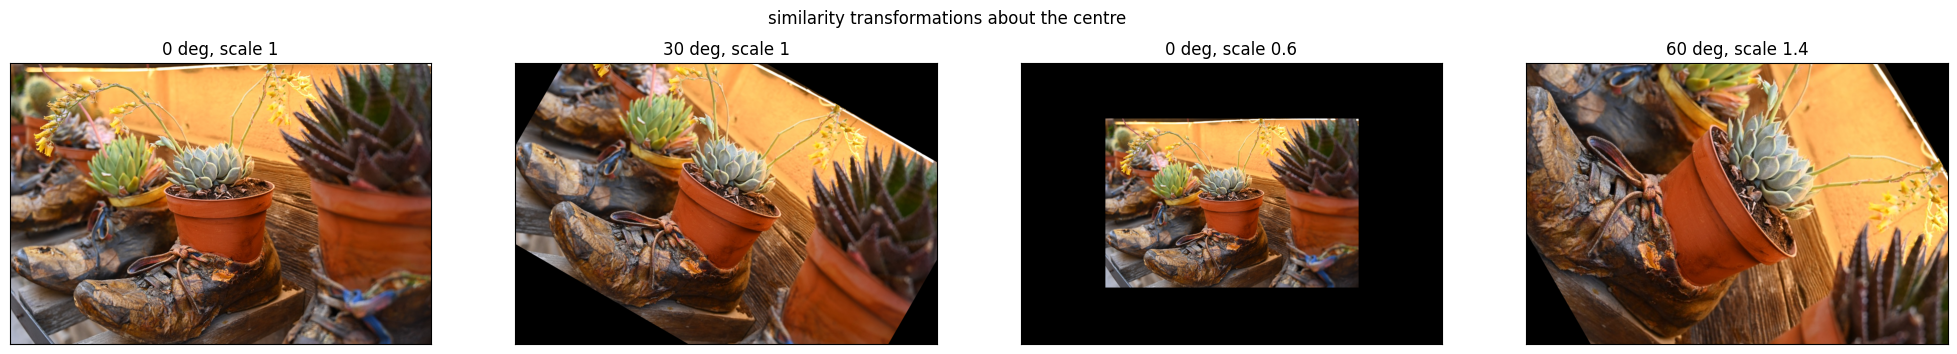

In [16]:
img = cv2.imread('image.jpg')
vis = Visualizer(1, 4, figsize=(25, 4), title='similarity transformations about the centre')
for i, (angle, scale) in enumerate([(0, 1), (30, 1), (0, 0.6), (60, 1.4)]):
    T = similarity_about_centre(angle, scale, img.shape[1], img.shape[0])
    vis.add_image_subplot(0, i, cv2.warpPerspective(img, T, (img.shape[1], img.shape[0])), title_str=f'{angle} deg, scale {scale}')

Write a function that detects keypoints with a given detector, warps the image and the keypoint coordinates (homogenise after warping!), and detects keypoints in the warped image. Then compute the repeatability. Avoid Python loops over keypoint pairs: compute all pairwise distances with NumPy broadcasting.

In [17]:
def detect_and_warp(img, T, detector):
    kp = detector.detect(img, None)
    points = np.array([k.pt for k in kp])  # N x 2 array of (x, y)
    H, W = img.shape[:2]

    #warp the image
    img_warped = cv2.warpAffine(
        img,
        T[:2, :],
        (W, H)
    )
    #convert points to homogeneous coordinates
    points_h = np.column_stack((points, np.ones(len(points))))

    warped_h = (T @ points_h.T).T

    # Homogenise
    points_gt = warped_h[:, :2] / warped_h[:, 2:3]



    kp_detected = detector.detect(img_warped, None)


    points_detected = np.array([k.pt for k in kp_detected])
    return points_gt, points_detected, img_warped


def repeatability(points_gt, points_detected, img_shape, threshold=5):
    # TODO: keep ground-truth points inside the image
    # TODO: fraction of ground-truth points with a detection closer than threshold

    H, W = img_shape[:2]

    #Keep ground-truth points inside the image
    valid = (
        (points_gt[:, 0] >= 0) &
        (points_gt[:, 0] < W) &
        (points_gt[:, 1] >= 0) &
        (points_gt[:, 1] < H)
    )

    points_gt = points_gt[valid]

    if len(points_gt) == 0:
        return np.nan

    if len(points_detected) == 0:
        return 0.0


    diff = points_gt[:, None, :] - points_detected[None, :, :]
    distances = np.linalg.norm(diff, axis=2)

    # Find nearest detected point for each ground-truth point
    min_distances = np.min(distances, axis=1)

    # Compute repeatability
    return np.mean(min_distances < threshold)
    return 0

In [18]:
img = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
sift = cv2.SIFT_create()
T = similarity_about_centre(15, 1, img.shape[1], img.shape[0])
points_gt, points_detected, img_warped = detect_and_warp(img, T, sift)
print(f'SIFT repeatability at 15 degrees: {repeatability(points_gt, points_detected, img.shape) * 100:.1f}%')  # about 89%

SIFT repeatability at 15 degrees: 88.8%


Plot the repeatability of SIFT as a function of the rotation angle (0 to 90 degrees in steps of 15) and of the scale (0.5 to 2). Answer:
* Which angle stands out from the others, and why?
* Why does it drop for both shrinking and enlarging the image?


Apart from 0°, the 90° rotation stands out because it aligns with the pixel grid and no interpolation is required.Thus image details and features are preserved.

Repetability decreases when shrinking or enlarging. Details of image are lost during shinrinking, and enlarging can change the image structures and features of the image so they mey no longer be deteacted.

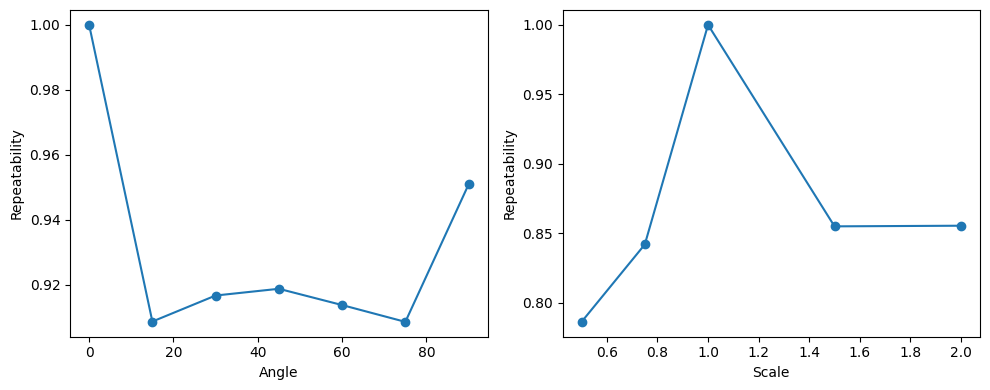

In [21]:
angles = np.arange(0, 91, 15)
scales = [0.5, 0.75, 1.0, 1.5, 2.0]

img_sift = image_gray.astype(np.uint8)

H, W = img_sift.shape[:2]
detector = cv2.SIFT_create()

def get_score(angle, scale):
    T = similarity_about_centre(angle, scale, W, H)
    gt, detected, warped = detect_and_warp(img_sift, T, detector)
    return repeatability(gt, detected, warped.shape)

angle_scores = [get_score(a, 1.0) for a in angles]
scale_scores = [get_score(0, s) for s in scales]

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(angles, angle_scores, 'o-')
plt.xlabel("Angle")
plt.ylabel("Repeatability")

plt.subplot(1, 2, 2)
plt.plot(scales, scale_scores, 'o-')
plt.xlabel("Scale")
plt.ylabel("Repeatability")

plt.tight_layout()
plt.show()

**Is this number meaningful?** A detector that fires everywhere would also re-find "its" keypoints. Compare SIFT with another detector and with chance:
* ORB (`cv2.ORB_create(2000)`), a much faster detector,
* a *random* detector (the chance level): replace the detections in the warped image by the same number of uniformly random points.

What would be a fairer way to compare detectors?

We could compare repeatability at a fixed number of keypoints and use uniformly random points as a baseline. This would help distinguish genuinely repeatable features from neary by match  due to high keypoint density.

In [23]:
# TODO: compare SIFT, ORB and random points at 45 degrees
T = similarity_about_centre(45, 1.0, W, H)

detectors = {
    "SIFT": cv2.SIFT_create(nfeatures=500),
    "ORB": cv2.ORB_create(nfeatures=500)
}

for name, detector in detectors.items():
    gt, detected, warped = detect_and_warp(img_sift, T, detector)
    score = repeatability(gt, detected, warped.shape)
    print(name, score)

class RandomDetector:
    def detect(self, img, mask=None):
        H, W = img.shape[:2]
        xs = np.random.uniform(0, W, 500)
        ys = np.random.uniform(0, H, 500)
        return [cv2.KeyPoint(float(x), float(y), 1)
                for x, y in zip(xs, ys)]

random_detector = RandomDetector()

gt, detected, warped = detect_and_warp(img_sift, T, random_detector)
random_score = repeatability(gt, detected, warped.shape)

print("Random:", random_score)

SIFT 0.8023809523809524
ORB 0.847926267281106
Random: 0.02040816326530612


### Optional Task
Instead of `cv2.findHomography`, compute a homography yourself from 4 correspondences using the DLT: set up $A$ and solve $Ah = 0$ with `np.linalg.svd` (Lecture 5). Compare your result to `cv2.findHomography`, which normalises such that $h_{3,3} = 1$.

In [ ]:
def homography_svd(points_a, points_b):
    # TODO: points are N x 2 arrays; return the normalised 3x3 homography
    return None

points_a = np.float32([[0, 0], [0, 100], [100, 100], [100, 0]])
points_b = points_a + np.float32(np.random.uniform(-10, 10, size=points_a.shape))
print(cv2.findHomography(points_a, points_b)[0])
print(homography_svd(points_a, points_b))

## Problem 1.3 - Image Stitching and RANSAC

In the lecture we have seen how we can use homographies to warp images. We will now use SIFT to obtain point correspondences to estimate a homography between to images. We can then use the estimated homography to stitch images into a panorama.

We will start where the lecture left off: we compute a homography from manual correspondences to show that the stitched image is reasonable. The reason why `stitch_images()` below is so lengthy is that we need to be careful with our coordinate systems. Since $[0,0]$ is always the first element in a numpy array, we need to convert between pixel coordinates and array indices after applying the homography. We do this by transforming the 4 corners of one image to the other which will give us the the mapping between array indices and coordinates so that we can blend the images properly.

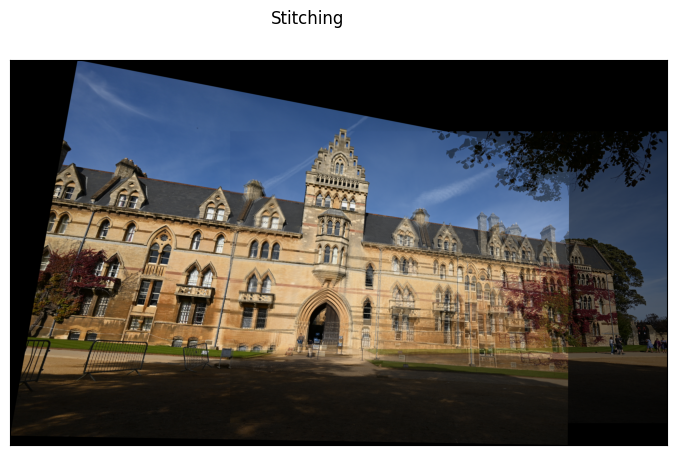

In [25]:
def stitch_images(img2, img1, homography):
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]

    corners1 = np.float32([[0, 0], [0, h1], [w1, h1], [w1, 0]]).reshape(-1, 1, 2)
    corners2 = np.float32([[0, 0], [0, h2], [w2, h2], [w2, 0]]).reshape(-1, 1, 2)
    warped_corners2 = cv2.perspectiveTransform(corners2, homography)

    corners = np.concatenate((corners1, warped_corners2), axis=0)
    [xmin, ymin] = np.int32(corners.min(axis=0).ravel() - 0.5)
    [xmax, ymax] = np.int32(corners.max(axis=0).ravel() + 0.5)

    t = [-xmin, -ymin]
    Ht = np.array([[1, 0, t[0]], [0, 1, t[1]], [0, 0, 1]])

    warped_img2 = cv2.warpPerspective(img2, Ht @ homography, (xmax - xmin, ymax - ymin))
    warped_img2[t[1]:h1 + t[1], t[0]:w1 + t[0]] = warped_img2[t[1]:h1 + t[1], t[0]:w1 + t[0]] // 2 + img1 //2

    return warped_img2

downsample = 0.25  # to make things faster we will resize the images
points1 = np.float32([[2597, 1004], [3123, 1013], [3140, 1275], [2577, 1268]]).reshape(4, 2) * downsample
points2 = np.float32([[1165, 726], [1770, 828], [1768, 1109], [1115, 1009]]).reshape(4, 2) * downsample

homography, status = cv2.findHomography(points1, points2)

image1_color = cv2.resize(cv2.imread('image_cc_1.jpg'), (0,0), fx=downsample, fy=downsample)
image2_color = cv2.resize(cv2.imread('image_cc_2.jpg'), (0,0), fx=downsample, fy=downsample)

# visualize the result
vis = Visualizer(1, 1, figsize=(25,5), title='Stitching')
vis.add_image_subplot(0, 0, stitch_images(image1_color, image2_color, homography))

The overlay is reasonable but not perfect in many places. Let us use SIFT correspondences instead. We use the *ratio test* from the SIFT paper to filter out ambiguous matches: a match is kept only if its descriptor distance is clearly smaller (factor 0.75) than that of the second-best match.

* Randomly pick 4 matches (`random.sample()`), estimate a homography from them and stitch.
* Run it several times. Why does this only sometimes work?

2355 matches after the ratio test


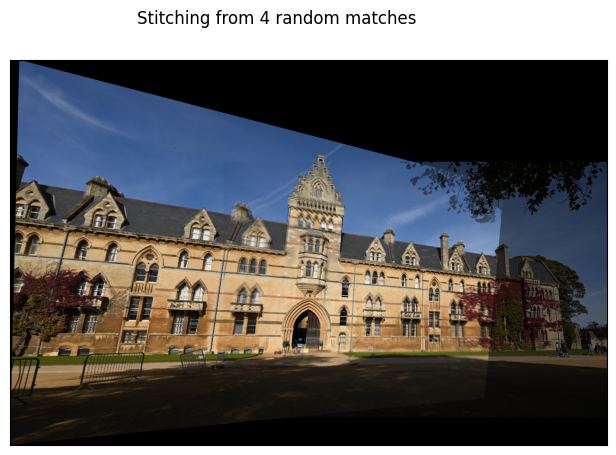

In [28]:
image1_gray = cv2.cvtColor(image1_color, cv2.COLOR_BGR2GRAY)
image2_gray = cv2.cvtColor(image2_color, cv2.COLOR_BGR2GRAY)
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(image1_gray, None)
kp2, des2 = sift.detectAndCompute(image2_gray, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)  # the two best matches per descriptor
matches = [m for m, n in matches if m.distance < 0.75 * n.distance]  # ratio test
print(f'{len(matches)} matches after the ratio test')
points1 = np.float32([kp1[m.queryIdx].pt for m in matches])
points2 = np.float32([kp2[m.trainIdx].pt for m in matches])

# TODO: randomly select 4 matches and compute a homography from them
# Randomly select 4 correspondences
idx = random.sample(range(len(matches)), 4)

# Compute homography
homography, _ = cv2.findHomography(
    points1[idx],
    points2[idx],
    0
)
vis = Visualizer(1, 1, figsize=(25, 5), title='Stitching from 4 random matches')
vis.add_image_subplot(0, 0, stitch_images(image1_color, image2_color, homography))

RANdom SAmple Consensus (RANSAC) to the rescue: repeatedly fit a homography to 4 random matches, count the *inliers* (matches whose point in image 1, mapped with the homography, lands within `threshold` pixels of its match in image 2), and keep the homography with the most inliers. Finally, **refit** the homography by least squares on all inliers of the best model (`cv2.findHomography` with all inlier points and method `0`), and return the refitted homography together with *its* inliers (count them again).

Count the inliers without a Python loop over the matches.

Number of inliers: 283
Number of inliers: 933
Number of inliers: 1580
Number of inliers: 2068
Number of inliers: 2069
Number of inliers: 2075
Number of inliers: 2087


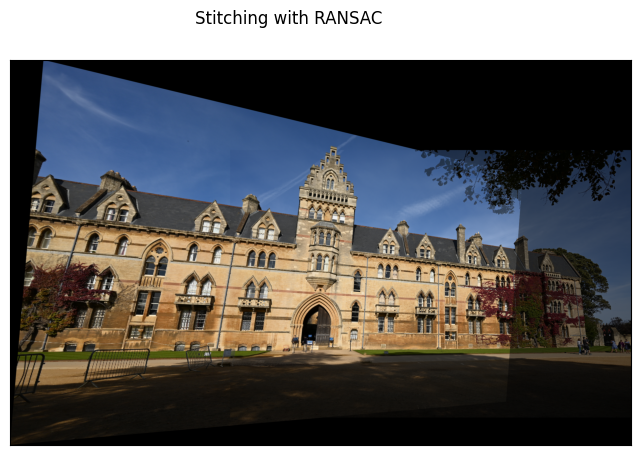

In [31]:
def count_inliers(homography, points1, points2, threshold):
    #Convert to homogeneous coordinates
    points1_h = np.column_stack((points1, np.ones(len(points1))))

    #Warp points
    warped_h = (homography @ points1_h.T).T

    #Homogenise
    warped = warped_h[:, :2] / warped_h[:, 2:3]

    #Compute distances
    distances = np.linalg.norm(warped - points2, axis=1)

    #Return boolean array
    return distances < threshold


def ransac(points1, points2, num_iterations=1000, threshold=3.0, verbose=True):
    best_homography, best_inliers = None, np.zeros(len(points1), bool)
    # TODO: implement RANSAC; print the number of inliers whenever you find a better homography
    # TODO: refit on all inliers of the best model, and recount the inliers of the refitted homography

    for i in range(num_iterations):
        # Randomly select 4 matches
        idx = random.sample(range(len(points1)), 4)

        # Compute homography
        H, _ = cv2.findHomography(points1[idx], points2[idx], 0)

        if H is None:
            continue

        # Count inliers
        inliers = count_inliers(H, points1, points2, threshold)

        # Keep the best homography
        if np.sum(inliers) > np.sum(best_inliers):
            best_homography = H
            best_inliers = inliers

            if verbose:
                print("Number of inliers:", np.sum(best_inliers))

    # Refit using all inliers
    if np.sum(best_inliers) < 4:
        return best_homography, best_inliers

    best_homography, _ = cv2.findHomography(
        points1[best_inliers],
        points2[best_inliers],
        0
    )

    # Recount inliers
    best_inliers = count_inliers(
        best_homography, points1, points2, threshold
    )
    return best_homography, best_inliers

homography, inliers = ransac(points1, points2)
vis = Visualizer(1, 1, figsize=(25, 5), title='Stitching with RANSAC')
vis.add_image_subplot(0, 0, stitch_images(image1_color, image2_color, homography))

**How many iterations are enough?** If a fraction $w$ of the matches are inliers, a random sample of 4 is all-inlier with probability $w^4$. To find at least one such sample with probability $p$, RANSAC needs
$$N = \frac{\log(1 - p)}{\log(1 - w^4)}$$
iterations.
* Estimate $w$ from your result and compute $N$ for $p = 0.99$.
* Check this empirically: run RANSAC with $N$ iterations (and `verbose=False`) 50 times and count how often it finds at least 90% of the inliers of your best model. Does this match $p$?
* How does $N$ change if only 20% of the matches were correct? Why is the minimal sample size so important?

If only 20% of the matches are correct, the required number of RANSAC iterations increases from 6 to 2876 for a 99% success probability. The minimal sample size is important because using fewer points increases the probability of selecting an all-inlier sample, reducing the number of RANSAC iterations needed.

In [38]:
# TODO: estimate w, compute N, and verify empirically

print("Total matches:", len(matches))
print("Final inliers:", np.sum(inliers))

w = np.mean(inliers)
p = 0.99

N = int(np.ceil(
    np.log(1 - p) / np.log(1 - w**4)
))

print("Inlier ratio:", w)
print("Required iterations:", N)

best_count = np.sum(inliers)
successes = 0

for i in range(50):
    H, new_inliers = ransac(
        points1, points2,
        num_iterations=N,
        verbose=False
    )

    if np.sum(new_inliers) >= 0.9 * best_count:
        successes += 1

print("Successful runs:", successes)
print("Empirical success rate:", successes / 50)


w = 0.2
p = 0.99

N = int(np.ceil(np.log(1-p) / np.log(1-w**4)))
print("Runs for w=0.2, N=", N)  # 2876

Total matches: 2355
Final inliers: 2070
Inlier ratio: 0.8789808917197452
Required iterations: 6
Successful runs: 47
Empirical success rate: 0.94
Runs for w=0.2, N= 2876


### Optional Tasks

* Compare your result to OpenCV's built-in version, `cv2.findHomography(points1, points2, cv2.RANSAC, 3.0)`.
* Stitch a third image (`image_cc_3.jpg`) to the two previous ones. This is much harder: the view changes a lot, and in the frame of the first image some corners of the third one map behind the camera ($w < 0$). Choose the reference image carefully.